<a href="https://colab.research.google.com/github/0xkanagaraj/cat-dog-cnn-classifier/blob/main/cat_dog_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN for Dog–Cat Image Classification (3 Convolutional Layers)

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_datasets as tfds
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the dataset

The *cats_vs_dogs* dataset from TensorFlow Datasets (about 23,000 labeled images). It is downloaded automatically on the first run, which can take a few minutes. The data is split 70% train, 15% validation and 15% test.

In [3]:
!pip install -q importlib_resources
!rm -rf /root/tensorflow_datasets/cats_vs_dogs

In [4]:
(train_raw, val_raw, test_raw), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True)

class_names = info.features["label"].names   # ['cat', 'dog'] -> cat = 0, dog = 1
print("Classes:", class_names)
print("Train:", len(train_raw), "| Val:", len(val_raw), "| Test:", len(test_raw))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.MB2LVU_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Classes: ['cat', 'dog']
Train: 16283 | Val: 3490 | Test: 3489


## 3. Preprocess and build input pipelines

In [5]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def prep(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(tf.round(image), tf.uint8)       # uint8 keeps the cache small
    label = tf.reshape(tf.cast(label, tf.float32), [1])
    return image, label

def to_float(image, label):
    return tf.cast(image, tf.float32), label

def make_ds(ds, training=False):
    ds = ds.map(prep, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2000, seed=42)
    return ds.batch(BATCH_SIZE).map(to_float, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

train_ds = make_ds(train_raw, training=True)
val_ds = make_ds(val_raw)
test_ds = make_ds(test_raw)

## 4. Visualize sample images

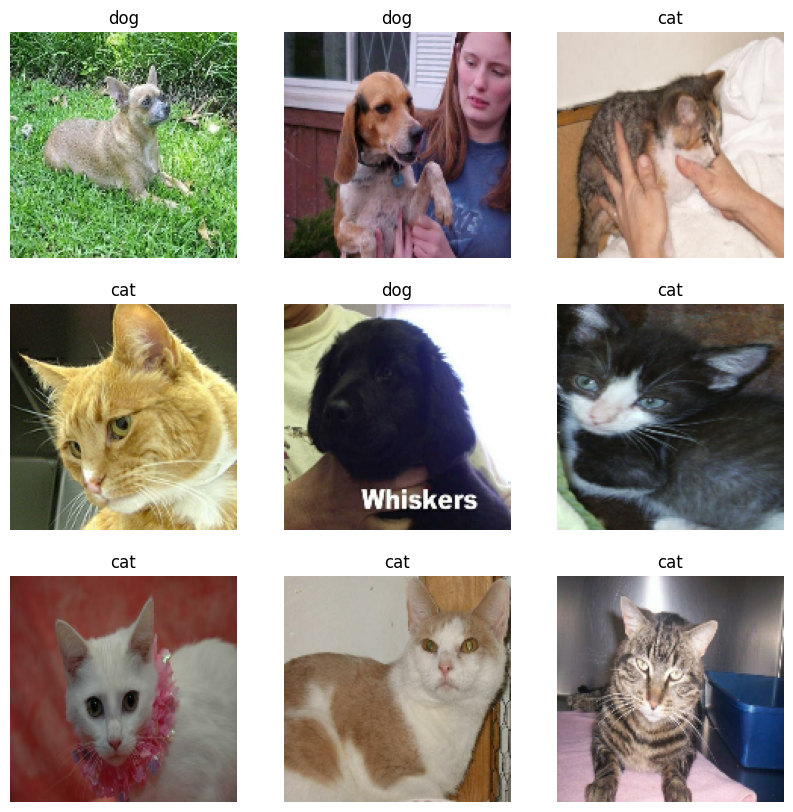

In [6]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.show()

## 5. Build the CNN (three convolutional layers)

In [7]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

model = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    data_augmentation,
    layers.Rescaling(1.0 / 255),

    # Convolutional block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Convolutional block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Convolutional block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Classifier head
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Train

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=40,
                    callbacks=callbacks, verbose=1)

Epoch 1/40
509/509 ━━━━━━━━━━━━━━━━━━━━ 36s 54ms/step - accuracy: 0.5914 - loss: 0.6627 - val_accuracy: 0.6404 - val_loss: 0.6222 - learning_rate: 0.0010
Epoch 2/40
509/509 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.6958 - loss: 0.5800 - val_accuracy: 0.7516 - val_loss: 0.5105 - learning_rate: 0.0010
Epoch 3/40
509/509 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.7438 - loss: 0.5162 - val_accuracy: 0.7805 - val_loss: 0.4696 - learning_rate: 0.0010
Epoch 4/40
509/509 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.7607 - loss: 0.4912 - val_accuracy: 0.7788 - val_loss: 0.5063 - learning_rate: 0.0010
Epoch 5/40
509/509 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.7794 - loss: 0.4636 - val_accuracy: 0.8181 - val_loss: 0.4157 - learning_rate: 0.0010
Epoch 6/40
509/509 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.7943 - loss: 0.4388 - val_accuracy: 0.8181 - val_loss: 0.4101 - learning_rate: 0.0010
Epoch 7/40
509/509 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.8041 - l

## 7. Training curves

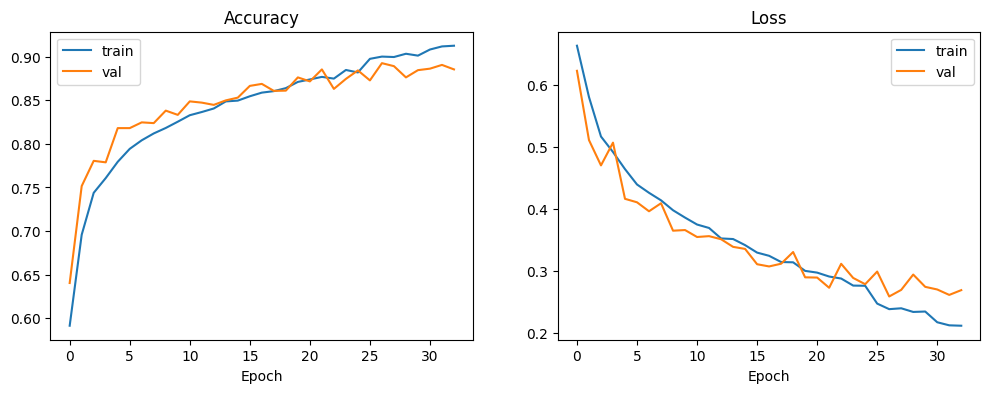

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

## 8. Evaluate on the test set

Test loss: 0.2484 | Test accuracy: 0.8948
              precision    recall  f1-score   support

         cat       0.91      0.87      0.89      1720
         dog       0.88      0.92      0.90      1769

    accuracy                           0.89      3489
   macro avg       0.90      0.89      0.89      3489
weighted avg       0.90      0.89      0.89      3489



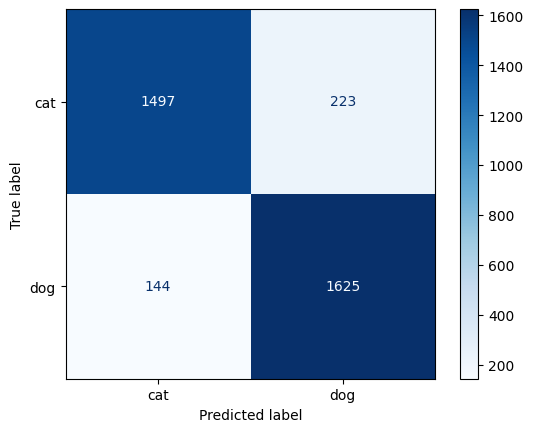

In [10]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

y_true = np.concatenate([y.numpy() for _, y in test_ds]).ravel().astype(int)
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=class_names).plot(cmap="Blues")
plt.show()

## 9. Sample predictions

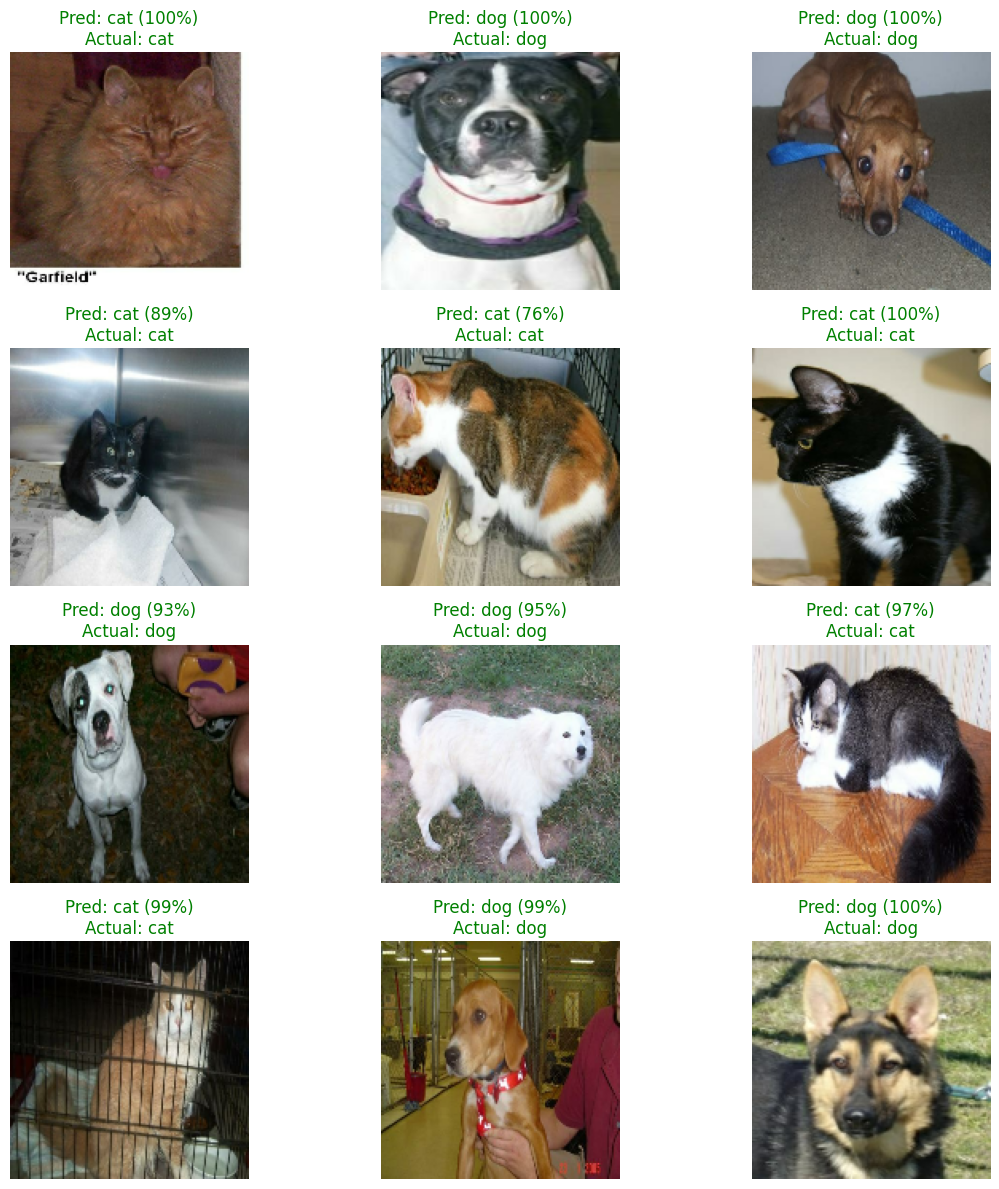

In [11]:
plt.figure(figsize=(12, 12))
for images, labels in test_ds.take(1):
    probs = model.predict(images, verbose=0).ravel()
    for i in range(12):
        plt.subplot(4, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        pred = int(probs[i] > 0.5)
        actual = int(labels[i])
        color = "green" if pred == actual else "red"
        conf = probs[i] if pred == 1 else 1 - probs[i]
        plt.title(f"Pred: {class_names[pred]} ({conf:.0%})\nActual: {class_names[actual]}", color=color)
        plt.axis("off")
plt.tight_layout()
plt.show()

## 10. Save the model

In [12]:
model.save("cat_dog_cnn.keras")
print("Model saved to cat_dog_cnn.keras")

Model saved to cat_dog_cnn.keras


## 11. Predict on your own image (optional)

Run this cell and upload a dog or cat photo.

In [13]:
from google.colab import files

uploaded = files.upload()
for name in uploaded:
    img = keras.utils.load_img(name, target_size=IMG_SIZE)
    arr = np.expand_dims(keras.utils.img_to_array(img), axis=0)
    p = float(model.predict(arr, verbose=0)[0][0])
    label = class_names[int(p > 0.5)]
    conf = p if p > 0.5 else 1 - p
    plt.imshow(img); plt.axis("off")
    plt.title(f"{label} ({conf:.0%})")
    plt.show()